# $Rocio$ $Argote$

## RUT: 22.373.783-8

#### Tarea 6: Análisis de un catalogo estelar mediante la funcion clases.


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

##### PARTE 1: construccion de la clase. 
Antes de empezar el catálogo, la tarea a sido pedida en el formato Docstring, en donde los parametros son los valores de entrada en la funcion, y los atributos son las variables internas de una clase, en donde se almacenan datos o características.


In [64]:
class CatalogoEstelar:
    """ Repesenta la creacion del catalogo. """

    def __init__(self, ruta_npz):
        """
        Init se ejecuta automaticamente para iniciar el 
        programa/catalogo y self representa el objeto.

        Parametros
        ♡ ────────────────── ♡
        ruta_npz = string
        esta ruta del archivo npz tiene los datos de las 
        estrellas, por eso ayudara a conocer su ubicacion.


        Atributos
        ♡ ────────────────── ♡
        datos del catalogo = pd.DataFrames
        un DataFrame de pandas es una estructura de 
        datos bidimensional (Tabla con filas y columnas)

        """
        self.ruta_npz = ruta_npz         #se guarda la ruta del archivo npz
        self.datos = self.cargar_npz()   #y esto ayuda a cargar los datos
        self.limpiar_datos()             #esto limpiara los datos automaticamente



    def cargar_npz(self):
        """
        Esta funcion se encargara de leer los datos del archivo dentro 
        de un DataFrame (Tabla), y queremos que esos datos se retornen.
    
        Retorna
        ♡ ────────────────── ♡
        pd.DataFrame retorna una tabla con los nombres dentro del archivo; 
        luminosidades, distancias, sus nombres y sus temperaturas.

        """
        archivo_npz = np.load(self.ruta_npz, allow_pickle=True)  #se usa np.load para leer y cargar matrices (o arrays) dentro del archivo
                                                                 #allow_pickle=True se usa para cargar el archivo con datos de todo 
                                                                 #tipo como str, int, etc.

        self.datos = pd.DataFrame({ "nombres": archivo_npz["nombre"],  "L_Lsol": archivo_npz["L_Lsol"], 
                                   "T_K": archivo_npz["T_K"],  "d_pc": archivo_npz["d_pc"] })
        return self.datos




    def limpiar_datos(self):
        """
        Esta funcion se encargara de limpiar los datos invalidos que encuentre durante la carga del archivo,
        los datos invalidos se remplazan por NaN, luegose calculan la cantidad de valores faltantes y su 
        porcentaje. Finalmente estos datos concluyentes se retornan.

        Retorna
        ♡ ────────────────── ♡
        pn.DataFrame retorna una tabla con la cantidad de valores faltantes e invalidos y el porcentaje de estos.

        """

        columna_catalogo = ["L_Lsol", "d_pc", "T_K"]          #se eligen estas variables ya que son numericas/fisicas.
        for columna in columna_catalogo:                      #se usa ciclo for para poder recorrer en orden la matriz.
            datos_invalidos = self.datos[columna] <= 0        #esta linea verifica si cada dato de las columnas son negativos o positivos.
            self.datos.loc[datos_invalidos, columna] = np.nan #loc[] permite seleccionar una fila y una columna dependiendo de
                                                              #cierta condicion y cambiarlos por NaN.
        datos_faltantes = self.datos.isna().sum()             #se usa para contar cuántos valores nulos o vacíos (NaN) hay.

        tot_porcentaje =(datos_faltantes/len(self.datos))*100 #en esta linea se calcula el total del porcentaje sobre los datos faltantes


        resumen_datos = pd.DataFrame({ "datos faltantes": datos_faltantes, "total porcentaje": tot_porcentaje })
        self.resumenDat_faltantes = resumen_datos             #guardo el resumen de los datos y su porcentaje.

        return resumen_datos
 




    def calcular_flujo(self): 
        """
        En esta funcion se calcula el flujo bolomerico de cada estrella
        a partir de su luminosidad y distancia. Para aquello, se realiza
        una conversion de medidas.
        De luminosidad solar a vatios, de distancia de parsec a metros.
        Luego, retornar los datos obtenidos, para ello se uso pd.series


        Retorno
        ♡ ────────────────── ♡
        pd.series se utilizara para crear una tabla con solo una columna:
        el flujo bolometrico de cada estrella expresado W/m⁻²
        
        """
        #vemos las conversiones equivalentes;
        L_sol = 3.828e26  #luminosidad del Sol en vatios
        pc = 3.086e16     #equivalencia de un parsec en metros

        luminosidad_W = self.datos["L_Lsol"] * L_sol           #aqui se obtiene la columna de luminosidad del catalogo (solares), 
                                                               #para luego multiplicarla por la luminosidad pero en vatios.

        distancia_m = self.datos["d_pc"] * pc                  #se hace lo mismo para obtener la distancia en metros.

        flujo_B = luminosidad_W / (4 * np.pi * distancia_m**2) #se utiliza la formula entregada, para obtener el flujo bolometrico en W/m²

        self.datos["Fbol"] = flujo_B                           #se usa slef.datos["Fbol"] para luego guardar el flujo obtenido, dentro del dataframe
        return self.datos["Fbol"]




    def calcular_radio(self):
        """
        en esta funcion se calcula el radio de cada estrella
        utilizando de relacion la ley de stefan-boltzmann.
        Luego retornara una sola columna de radios solres de cada estrella,
        para eso, se utiliza pd.series


        Retorno
        ♡ ────────────────── ♡
        pd.series nos entregara en este caso lso radios de cada estrella obtenida en radios solares.
        
        """

        tem_sol = 5778  #se usa la temperatura efectiva del sol como referencia,
                        #ya que la formula dada compara la temperatura de cada estrella con la solar

        temperatura = self.datos["T_K"]     #aqui "llamamos" de nuevo a las temperatura de las estrellas del dataframe
        luminosidad = self.datos["L_Lsol"]  #lo mismo
        
        radio_sol = np.sqrt(luminosidad) * (tem_sol / temperatura)**2 #aplico la formula a los datos.
        self.datos["R_Rsol"] = radio_sol    #lo guardo para usarlo en el dataframe y crear una nueva columna
        return self.datos["R_Rsol"]




    def calcular_magnitud(self):
        """
        en esta funcion se calcula la magnitud bolometrica absoluta
        de las estrellas, y se retornan los valores obtenidos.


        Retorno
        ♡ ────────────────── ♡
        pd.series nos dara una columna de el resultado de las magnitudes de cada estrella. 
        
        """

        
        luminosidad = self.datos["L_Lsol"]                #"llamamos" la luminosidad de las estrellas del dataframe
        magnitud_B = 4.74 - 2.5 * np.log10(luminosidad)   #se usa la formula dada para calcularla.

        self.datos["Mbol"] = magnitud_B                   #y se guardan los datos obtenidos.
        return self.datos["Mbol"]




    def calcular_lambda_max(self):
        """
        aqui se calcula la longitud de onda maxima emision, mediante la 
        ley de desplazamiento de Wien, y se busca expresar los datos en 
        nanometros (nm) y retornar los datos obtenidos.


        Retorno
        ♡ ────────────────── ♡
        pd.series nos retornara las longitudes obtenidas en solo una columna,
        para luego agregarla al dataframe.
        
        """

        b = 2.8978e-3                           #b es la cte de Wien
        temperatura = self.datos["T_K"]         #volvemos a "llamar" a las temperaturas de las estrellas
        lambda_max = (b / temperatura) * 1e9    #1e9 se usa para convertir de metros a nanometros (nano=9)
                                                # ya que 1m = 1.000.000.000nm

        self.datos["lambda_max_nm"]= lambda_max #guardo los datos obtenidos en el dataframe
        return self.datos["lambda_max_nm"]



    def clasificar_deteccion(self, umbral=1e-4):
        """
        aqui clasificaremos la deteccion de estrellas a partir de 
        flujos biometricos, y luego retorna los datos obtenidos.

        
        Parametros
        ♡ ────────────────── ♡
        umbral = float ,representa el flujo minimo necesario para 
        detectar una estrella, expresado en W/m². Y se menciona que
        su valor predeterminado es 1e-4.

        Retorna
        ♡ ────────────────── ♡
        pd.Series retorna una columna que indica si las estrellas
        fueron detectadas, no detectadas o si su clasificacion es
        desconocida.
        
        """

        flujo_B = self.calcular_flujo()                                       #se llama al flujo biometrico de las estrellas
        deteccion = pd.Series(pd.NA, index=self.datos.index, dtype="boolean") #aqui se crea una columna de pd.series
                                                                              #donde todas las filas son NA o valores nulos
        validos = flujo_B.notna()                                             #notna seran aquellas estrellas que no tienen valores nulos
        
        deteccion.loc[validos] = flujo_B.loc[validos] >= umbral               #las estrellas validas se comparan con el umbral valido
        self.datos["detectada"] = deteccion                                   #se guardan los datos obtenidos
        return self.datos["detectada"]


    def estadisticas(self):
        """
        aqui se calcula estadisticas de las estrellas y retorna un dataframe
        con las estadisticas; medidas de tendencia central, dispersion y 
        posicion, como la media, mediana, desviacion estandar, minimo, maximo 
        y percentiles. Ademas de valores minimos y maximos de luminosidad,
        temperatura y radio.


        Retorna
        ♡ ────────────────── ♡
        pd.DataFrame retornara las estadisticas concluyentes en esta funcion,
        nombres de las estrellas con valores minimos y maximos de luminosidad
        biometrica, temperatura efectiva y radio estelar.
        
        """

        self.calcular_radio() 
        columnas = ["L_Lsol", "T_K", "R_Rsol"]  #seleccionamos las propiedades fisicas
                                                #que utilizaremos para calcular las estadisticas
        
        resumen_estadistico = self.datos[columnas].agg(["mean", "median", "std", "min", "max"]).T 
                                                #se usa agg() para calcular varias medidas,
                                                #estadisticas al mismo tiempo.
                                                #mean para el promedio.
                                                #median para la mediana.
                                                #std para la desviacion estandar.
                                                #min y max para valores minimos y maximos encontrados.
                                                #.T organiza los valores en filas.
        
        resumen_estadistico["percentil_25"] = self.datos[columnas].quantile(0.25)
                                                #este percentil indica aquellos valores debajo del 25%

        resumen_estadistico["percentil_50"] = self.datos[columnas].quantile(0.50)
                                                #indica que corresponde a la mediana de los datos
        
        resumen_estadistico["percentil_75"] = self.datos[columnas].quantile(0.75)
                                                #indica que el 75% este bajo ese valor


        resumen_estadistico["estrella_min"] = [self.datos.loc[self.datos[col].idxmin(), "nombres"] if self.datos[col].notna().any() else pd.NA 
                                               for col in columnas]
                                                #se buscan los nombres de las estrellas con los valores minimos
                                                #de cada propiedad mediante idxmin()

        resumen_estadistico["estrella_max"] = [self.datos.loc[self.datos[col].idxmax(), "nombres"] if self.datos[col].notna().any() else pd.NA 
                                               for col in columnas]
                                                #se buscan los nombres de las estrellas con los valores maximos
                                                #de cada propiedad mediante idxmax()

        self.resumen_estadistico = resumen_estadistico #guardo los datos
        return resumen_estadistico



    def resumen_por_temperatura(self, umbral=1e-4):
        """
        aqui se clasificaran las estrellas en tres grupos dependiendo
        de su temperatura efectiva: frias, intermedias y calientes.
        Se calculara la cantidad de estrellas, temperatura media,
        luminosidad media, mediana del flujo bolometrico y fraccion
        de estrellas detectadas.
        
        """

        self.clasificar_deteccion(umbral)                             #se calcula el flujo y se clasifican las estrellas segun el umbral.

        datos_validos = self.datos[self.datos["T_K"].notna()].copy()  #se seleccionan las estrellas que tienen una temperatura valida.

        datos_validos["grupo"] = pd.cut(
            datos_validos["T_K"],
            bins=[-np.inf, 5000, 7500, np.inf],
            labels=["Fria", "Intermedia", "Caliente"],
            right=False
        )
                                                                      #se clasifican las estrellas segun su temperatura.

        resumen_temperatura = datos_validos.groupby("grupo", observed=False).agg(
            cantidad_estrellas=("T_K", "count"),
            temperatura_media=("T_K", "mean"),
            luminosidad_media=("L_Lsol", "mean"),
            mediana_flujo=("Fbol", "median"),
            flujos_validos=("Fbol", "count"),
            estrellas_detectadas=("detectada", lambda x: x.eq(True).sum())
        )
                                                                     #se calculan las estadisticas de cada grupo mediante agg().

        resumen_temperatura["fraccion_detectadas"] = (
            resumen_temperatura["estrellas_detectadas"] /
            resumen_temperatura["flujos_validos"]
        )
                                                                     #se calcula la fraccion de estrellas detectadas.

        resumen_temperatura = resumen_temperatura.drop(
            columns=["flujos_validos", "estrellas_detectadas"]
        )
                                                                     #se eliminan las columnas auxiliares.

        self.resumen_temperatura = resumen_temperatura
        return resumen_temperatura

    

    
    def graficar_histogramas(self, bins=30):
        """
        aqui se realizara un diagrama de hertzsprung-russell,
        relacionando la temperatura efectiva con la luminosidad
        de las estrellas.
        Se usa una escala logaritmica para la luminosidad
        y se invertira el eje de temperatura.

        
        Parametros
        ♡ ────────────────── ♡
        bins = int, representa la cantidad de intervalos utilizados
        en cada histograma, su valor predeterminado es 30


        Retorna
        ♡ ────────────────── ♡
        Se retorna un grafico con la distribucion de las estrellas
        segun su temperatura y luminosidad.
        
        """
        
        self.calcular_radio()       #se calcula el radio de las estrellas.
        self.calcular_magnitud()    #se calcula la magnitud bolometrica.

        columnas = ["L_Lsol", "d_pc", "T_K", "R_Rsol", "Mbol"] #se seleccionan las propiedades que se representaran.

        titulos = ["Luminosidad bolometrica", "Distancia",
                   "Temperatura efectiva", "Radio estelar",
                   "Magnitud bolometrica absoluta"]

        unidades = ["Luminosidad (L/Lsol)", "Distancia (pc)",
                    "Temperatura (K)", "Radio (R/Rsol)",
                    "Magnitud bolometrica"]

        for columna, titulo, unidad in zip(columnas, titulos, unidades):
            datos_validos = self.datos[columna].dropna()       #se eliminan los datos faltantes de cada propiedad.

            plt.figure(figsize=(9, 7))                         #se establece el tamaño del grafico.
            
            plt.hist(datos_validos, bins=bins, color="palevioletred", edgecolor="black")
                                                               #se crea el histograma con la cantidad de intervalos indicada.
 
            plt.xlabel(unidad)                                 # eje x.                           
            plt.ylabel("Cantidad de estrellas")                # eje y.
            plt.title("Distribucion de " + titulo)             #se agrega un titulo.

            plt.grid(True, alpha=0.3)                          #se agrega una cuadricula.
            plt.show() 




    def graficar_temperatura_flujo(self, umbral=1e-4):
        """
        en esta funcion se relacionara la temperatura efectiva con el flujo
        bolometrico de las estrellas, utilizando dos graficos.

        Parametros
        ♡ ────────────────── ♡
        umbral = float, representa el flujo minimo necesario
        para detectar una estrella.

        Retorna
        ♡ ────────────────── ♡
        Se mostraran dos graficos: un histograma de temperaturas
        y un grafico de flujo bolometrico segun la distancia.
        
        """

        self.clasificar_deteccion(umbral)               #se calcula el flujo y se clasifican las estrellas.
        fig, ejes = plt.subplots(1, 2, figsize=(14, 6)) #se crean dos graficos en una misma figura.

                                                        #primer grafico: histograma de temperaturas.
        temperaturas = self.datos["T_K"].dropna()       #se seleccionan las temperaturas validas.

        ejes[0].hist(temperaturas, bins=30, color="palevioletred", edgecolor="black")
        ejes[0].set_xlabel("Temperatura (K)")           #eje x.
        ejes[0].set_ylabel("Cantidad de estrellas")     #eje y.
        ejes[0].set_title("Distribucion de temperaturas") #añado un titulo.
        ejes[0].grid(True, alpha=0.3)                   #esto agrega una cuadricula.

                                                        #segundo grafico: flujo bolometrico segun la distancia.
        datos_validos = self.datos.dropna(subset=["d_pc", "Fbol", "T_K"])
        datos_validos = datos_validos[datos_validos["Fbol"] > 0]
                                                        #se seleccionan las estrellas con datos validos.

        puntos = ejes[1].scatter(datos_validos["d_pc"], datos_validos["Fbol"],
                                 c=datos_validos["T_K"], cmap="plasma",
                                 s=5, alpha=0.5)
                                                        #representa el flujo segun la distancia y el color indica la temperatura.

        ejes[1].set_yscale("log")                       #se usa una escala logaritmica para el flujo.
        ejes[1].axhline(umbral, color="red", linestyle="--", label="Umbral de deteccion")
                                                        #se agrega una linea horizontal que representa el umbral.

        ejes[1].set_xlabel("Distancia (pc)")            #eje x.
        ejes[1].set_ylabel("Flujo bolometrico (W/m²)")  #eje y.
        ejes[1].set_title("Flujo bolometrico segun distancia") #se agrega un titulo.
        ejes[1].legend()

        fig.colorbar(puntos, ax=ejes[1], label="Temperatura (K)") #se agrega una barra de color.
        ejes[1].grid(True, alpha=0.3)                             #se agrega una cuadricula.

        plt.tight_layout()
        plt.show()





    def graficar_grupos(self, umbral=1e-4):
        """
        en esta funcion se graficaran los grupos de estrellas segun su
        temperatura efectiva, comparando la cantidad de estrellas
        y la fraccion de estrellas detectadas.

        Parametros
        ♡ ────────────────── ♡
        umbral = float, representa el flujo minimo necesario
        para detectar una estrella

        Retorna
        ♡ ────────────────── ♡
        nos retorna dos graficos de barras con los resultados
        obtenidos para cada grupo de temperatura.
        """

        resumen = self.resumen_por_temperatura(umbral)  #se obtiene el resumen de los tres grupos de temperatura.
        fig, ejes = plt.subplots(1, 2, figsize=(13, 6)) #se crean dos graficos en una misma figura.
        grupos = resumen.index

                                                        #primer grafico: cantidad de estrellas por grupo.
        ejes[0].bar(grupos, resumen["cantidad_estrellas"],
                    color="palevioletred", edgecolor="black")
        ejes[0].set_xlabel("Grupo de temperatura")
        ejes[0].set_ylabel("Cantidad de estrellas")
        ejes[0].set_title("Cantidad de estrellas por grupo")
        ejes[0].grid(axis="y", alpha=0.3)

                                                        #segundo grafico: fraccion de estrellas detectadas.
        ejes[1].bar(grupos, resumen["fraccion_detectadas"],
                    color="palevioletred", edgecolor="black")
        ejes[1].set_xlabel("Grupo de temperatura")
        ejes[1].set_ylabel("Fraccion detectada")
        ejes[1].set_title("Fraccion detectada por grupo")
        ejes[1].set_ylim(0, 1)
        ejes[1].grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.show()




    def guardar_resultados(self, nombre_archivo="catalogo_procesado.csv"):
        """
        aqui se guardaran los resultados obtenidos del catalogo
        procesado en un archivo CSV

        Parametros
        ♡ ────────────────── ♡
        nombre_archivo = string

        Retorna
        ♡ ────────────────── ♡
        retorna un archivo CSV con todas las propiedades
        calculadas de las estrellas.
        
        """

        self.calcular_flujo()       #se calcula el flujo bolometrico.
        self.calcular_radio()       #se calcula el radio estelar.
        self.calcular_magnitud()    #se calcula la magnitud bolometrica.
        self.calcular_lambda_max()  #se calcula la longitud de onda maxima.
        self.datos.to_csv(nombre_archivo, index=False)
                                    #se guardan todos los datos del catalogo en un archivo CSV.

        return nombre_archivo




    @classmethod
    def desde_dataframe(cls, dataframe):
            """
            aqui se creara un catalogo estelar directamente desde
            un DataFrame, sin necesidad de cargar un archivo NPZ.

            Parametros
            ♡ ────────────────── ♡
            dataframe = pd.DataFrame, contiene los nombres,
            luminosidades, distancias y temperaturas de las estrellas.

            Retorna
            ♡ ────────────────── ♡
            Se retorna una nueva instancia de CatalogoEstelar
            con los datos entregados.
            
            """

            catalogo = cls.__new__(cls)       #se crea una instancia sin ejecutar el init.

            catalogo.ruta_npz = None
            catalogo.datos = dataframe.copy() #se copian los datos para no modificar el DataFrame original.

            if "nombre" in catalogo.datos.columns:
                catalogo.datos = catalogo.datos.rename(columns={"nombre": "nombres"}) #se adapta el nombre de la columna al formato utilizado en la clase.

            columnas = ["nombres", "L_Lsol", "d_pc", "T_K"] #se verifican las columnas necesarias.

            if not all(columna in catalogo.datos.columns for columna in columnas):
                raise ValueError("El DataFrame no contiene todas las columnas necesarias.")

            catalogo.limpiar_datos() #se limpian los datos automaticamente.

            return catalogo

In [65]:
catalogo = CatalogoEstelar("catalogo_100000_estrellas.npz.zip")

In [66]:
resumen_temperatura = catalogo.resumen_por_temperatura()

print(resumen_temperatura)

            cantidad_estrellas  temperatura_media  luminosidad_media  \
grupo                                                                  
Fria                     24139        4001.734479          49.993467   
Intermedia               30397        6250.023700          50.236492   
Caliente                 30458        8744.869700          50.024197   

            mediana_flujo  fraccion_detectadas  
grupo                                           
Fria         1.909585e-11                  0.0  
Intermedia   1.917778e-11                  0.0  
Caliente     1.883511e-11                  0.0  


In [67]:
resumen_estadistico = catalogo.estadisticas()
print(resumen_estadistico)


               mean       median          std          min          max  \
L_Lsol    50.113039    50.262004    28.820631     0.101316    99.999374   
T_K     6505.530747  6511.134245  2016.436646  3000.122706  9999.904282   
R_Rsol     7.412279     5.069647     6.356226     0.113146    36.868159   

        percentil_25  percentil_50  percentil_75    estrella_min  \
L_Lsol     25.157857     50.262004     75.031325  Estrella_10217   
T_K      4755.441918   6511.134245   8254.480611   Estrella_5058   
R_Rsol      3.128667      5.069647      9.593870  Estrella_62716   

          estrella_max  
L_Lsol  Estrella_45903  
T_K     Estrella_70445  
R_Rsol   Estrella_2395  


In [68]:
print(catalogo.datos["T_K"].describe())

print(catalogo.datos["T_K"].apply(
    lambda x: "Fria" if x < 5000 else
    "Intermedia" if x < 7500 else
    "Caliente"
).value_counts())

count    84994.000000
mean      6505.530747
std       2016.436646
min       3000.122706
25%       4755.441918
50%       6511.134245
75%       8254.480611
max       9999.904282
Name: T_K, dtype: float64
T_K
Caliente      45464
Intermedia    30397
Fria          24139
Name: count, dtype: int64


In [69]:
resumen_temperatura = catalogo.resumen_por_temperatura()
print(resumen_temperatura.to_string())

            cantidad_estrellas  temperatura_media  luminosidad_media  mediana_flujo  fraccion_detectadas
grupo                                                                                                   
Fria                     24139        4001.734479          49.993467   1.909585e-11                  0.0
Intermedia               30397        6250.023700          50.236492   1.917778e-11                  0.0
Caliente                 30458        8744.869700          50.024197   1.883511e-11                  0.0


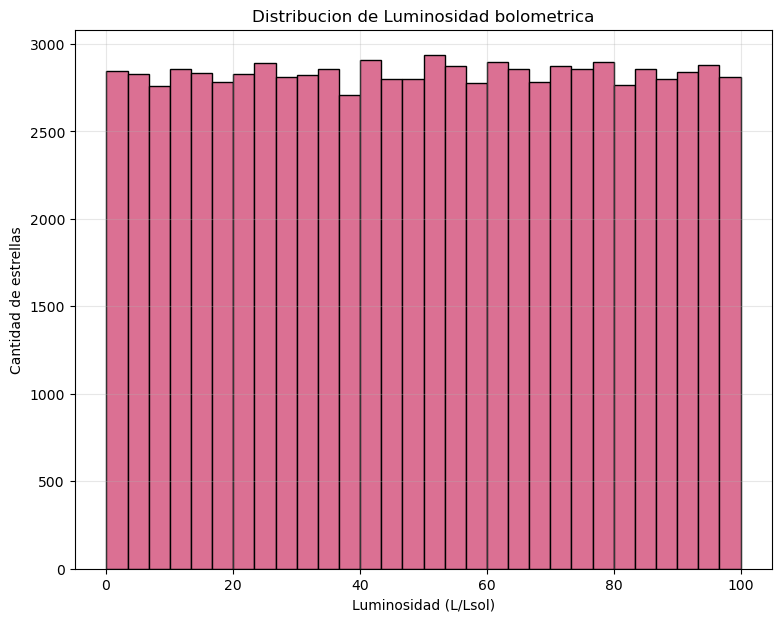

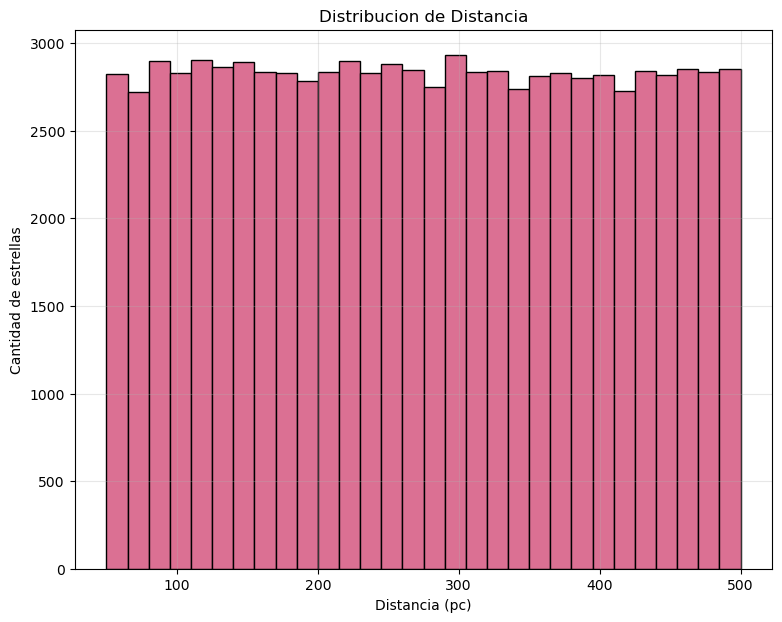

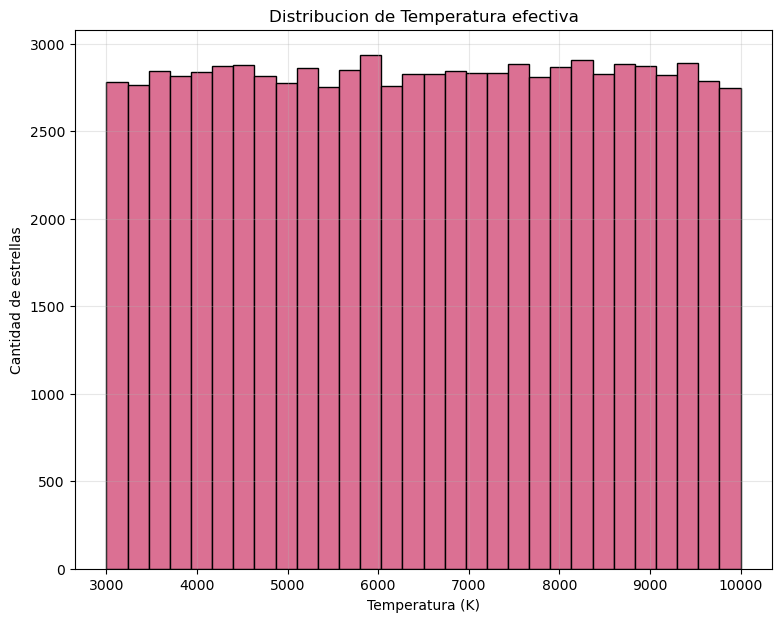

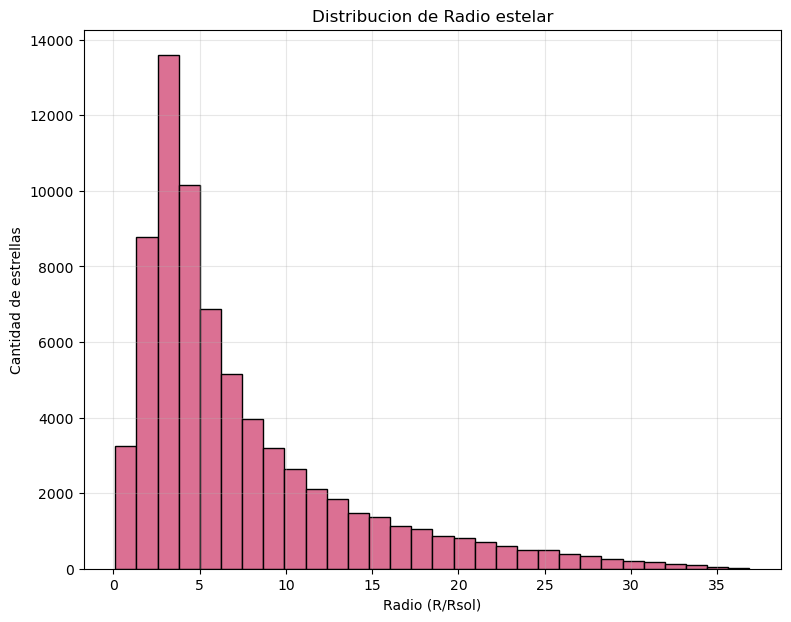

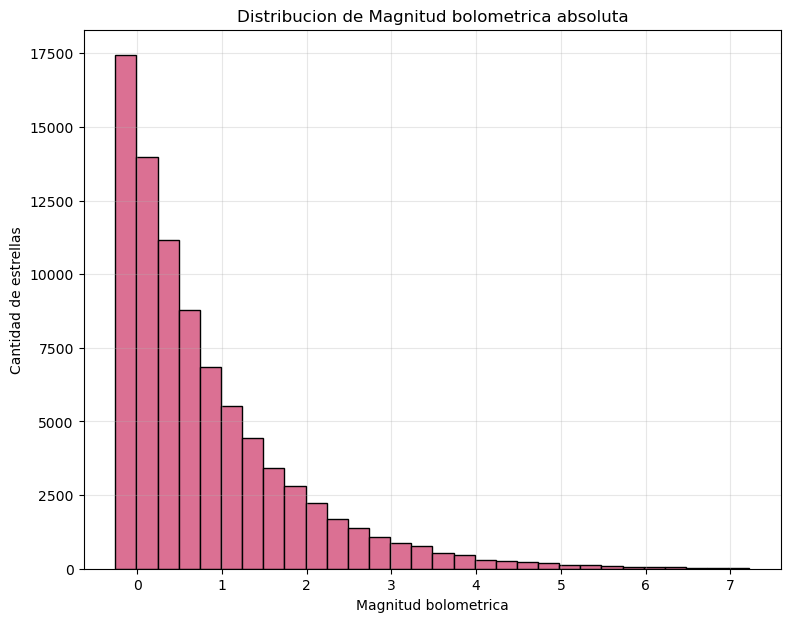

In [70]:

catalogo.graficar_histogramas()

<ipython-input-64-a3aa79c3efca>:425: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.tight_layout()
<ipython-input-64-a3aa79c3efca>:425: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  plt.tight_layout()
<ipython-input-64-a3aa79c3efca>:425: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.tight_layout()
<ipython-input-64-a3aa79c3efca>:425: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.tight_layout()


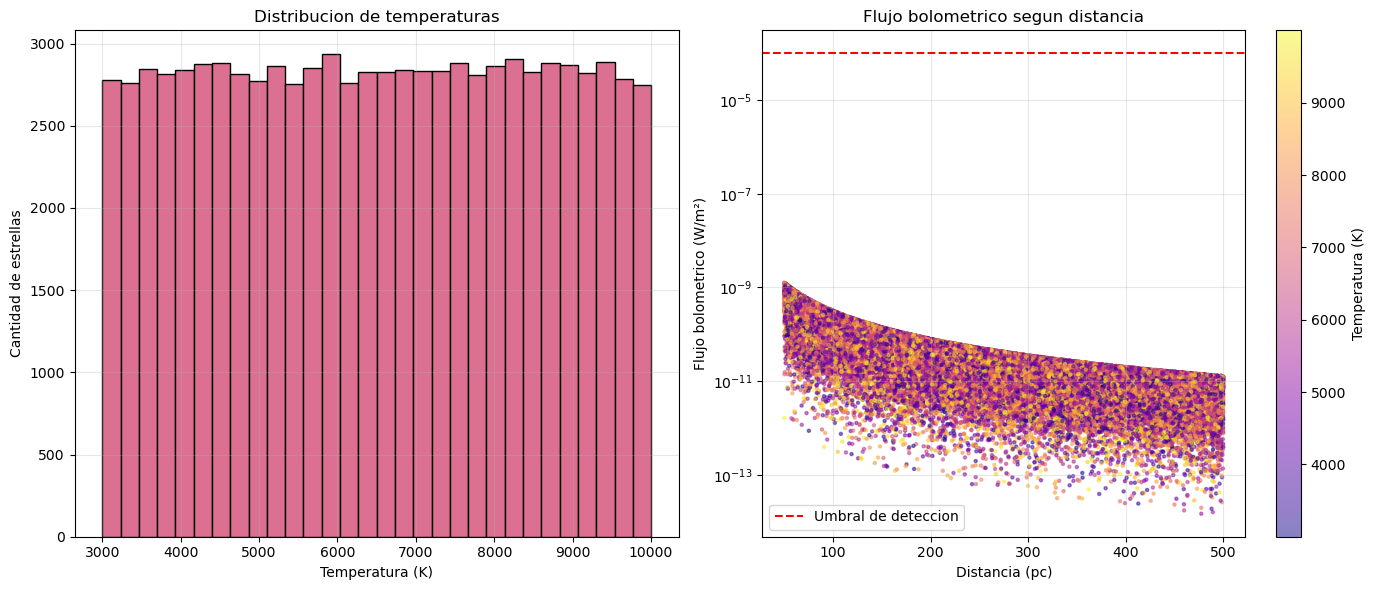

In [71]:
catalogo.graficar_temperatura_flujo()

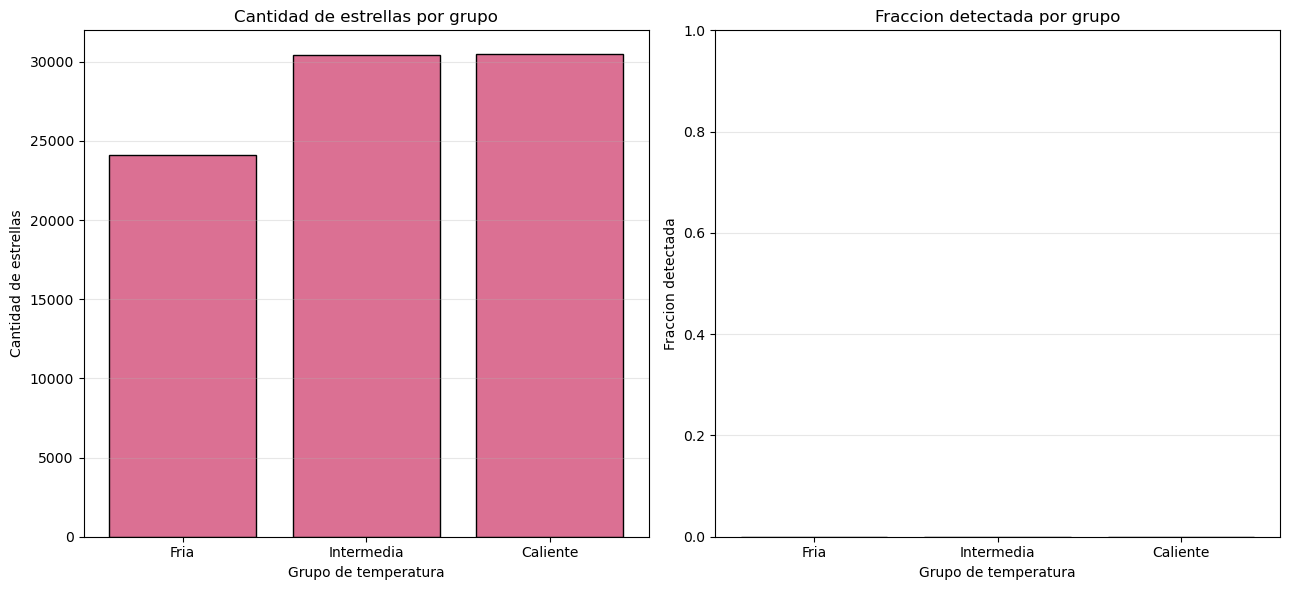

In [72]:
catalogo.graficar_grupos()

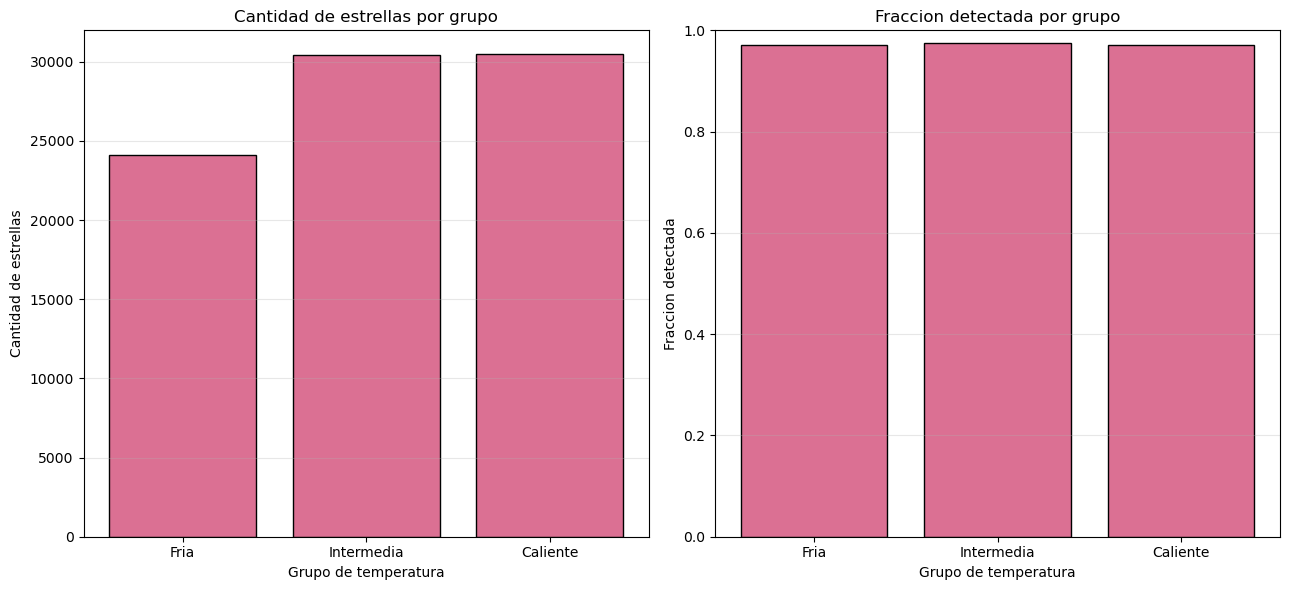

In [73]:
catalogo.graficar_grupos(umbral=1e-12)

In [74]:
catalogo.guardar_resultados()

'catalogo_procesado.csv'

In [75]:
datos_manual = pd.DataFrame({
    "nombre": ["Estrella_" + str(i) for i in range(1, 11)],
    "L_Lsol": [1, 2, 5, 10, 15, 20, 30, 40, 50, 60],
    "d_pc": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
    "T_K": [3000, 3500, 4000, 4500, 5000, 6000, 7000, 8000, 9000, 10000]
})


catalogo_manual = CatalogoEstelar.desde_dataframe(datos_manual)

In [76]:
catalogo_manual.calcular_flujo()
catalogo_manual.calcular_radio()
catalogo_manual.calcular_magnitud()
catalogo_manual.calcular_lambda_max()

0    965.933333
1    827.942857
2    724.450000
3    643.955556
4    579.560000
5    482.966667
6    413.971429
7    362.225000
8    321.977778
9    289.780000
Name: lambda_max_nm, dtype: float64

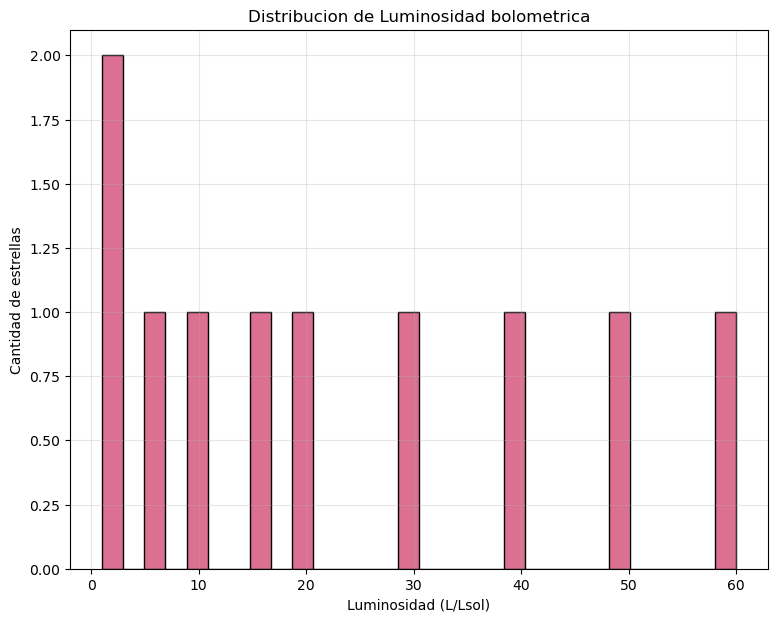

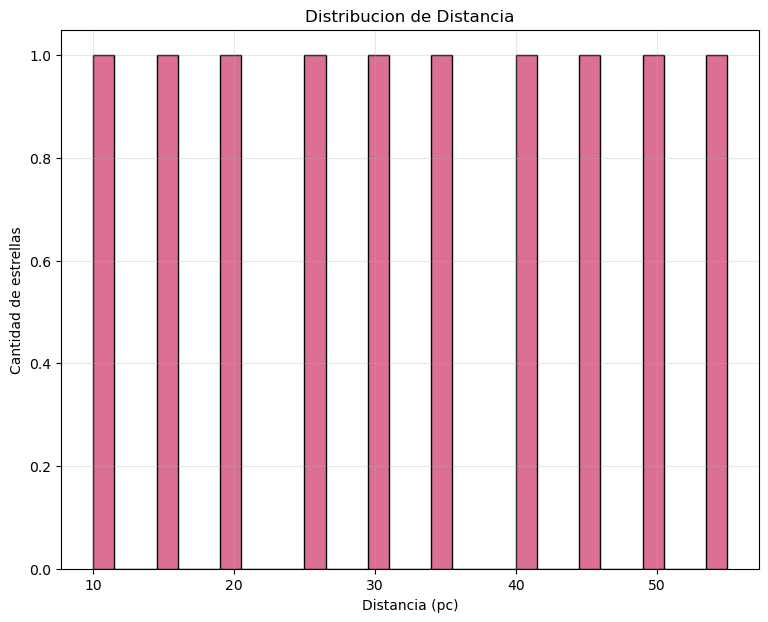

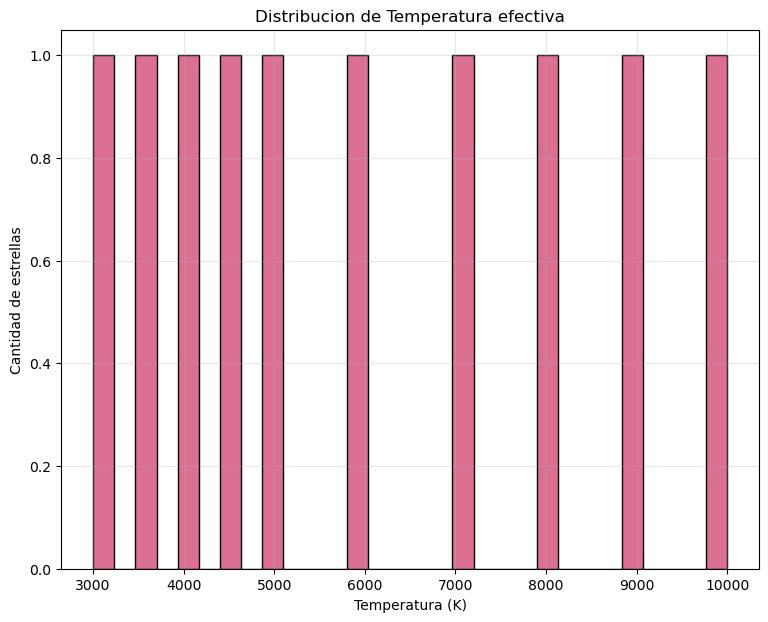

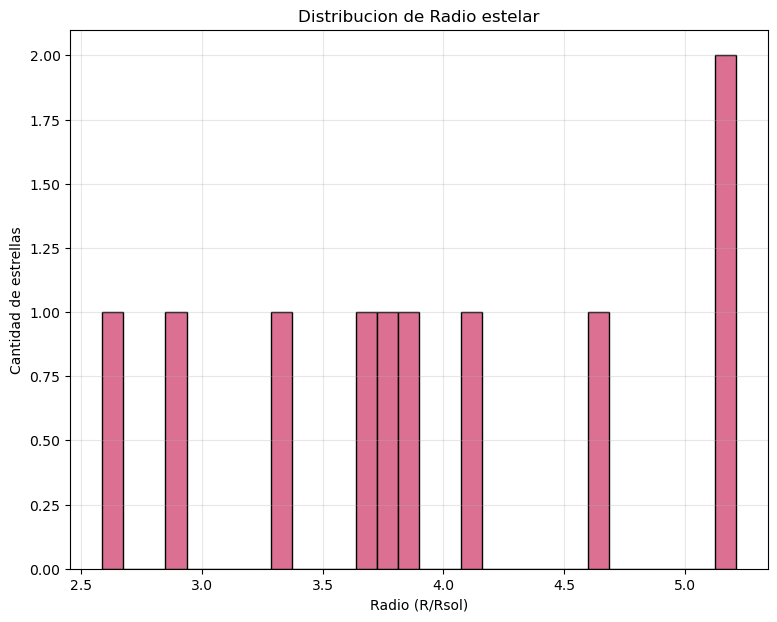

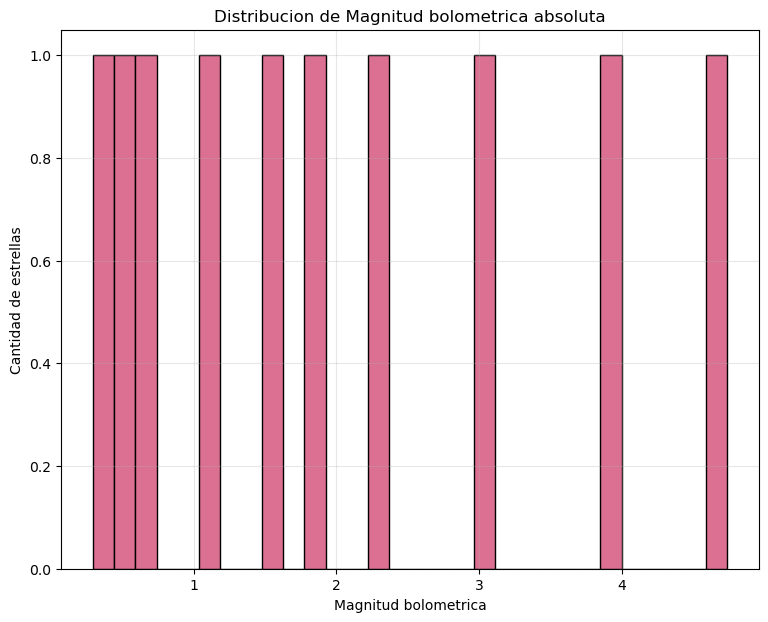

In [77]:
catalogo_manual.graficar_histogramas()